# Phase 3: Calibration Methods Comparison

## Goals
- Apply post-hoc calibration methods to baseline models
- Compare: Temperature Scaling, Platt, Isotonic, Beta, Histogram Binning
- Evaluate calibration quality under i.i.d. and temporal shift
- Add conformal prediction coverage analysis
- Determine which calibrator works best for fraud detection

In [3]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils.helpers import load_config, set_seed
from src.data.loader import load_creditcard, preprocess_creditcard
from src.data.splits import temporal_split_creditcard
from src.models.baselines import get_model
from src.calibration.post_hoc import get_calibrator, CALIBRATORS
from src.calibration.conformal import SplitConformalClassifier, CostAwareConformal
from src.evaluation.calibration_metrics import compute_all_calibration_metrics
from src.evaluation.visualization import (
    plot_reliability_diagram, plot_reliability_comparison
)

config = load_config('../configs/config.yaml')
set_seed(config['experiment']['seed'])
print('Setup complete.')

Setup complete.


In [4]:
# Load data and train best baseline (reuse from Phase 2)
# Split FIRST, then preprocess with train-only statistics (leakage-free)
df_raw = load_creditcard(f"../{config['data']['creditcard_path']}")
splits = temporal_split_creditcard(df_raw)
X, y = preprocess_creditcard(df_raw, train_idx=splits['train'])

X_train, y_train = X.iloc[splits['train']].values, y[splits['train']]
X_cal, y_cal = X.iloc[splits['calibration']].values, y[splits['calibration']]
X_test, y_test = X.iloc[splits['test']].values, y[splits['test']]

# Train XGBoost baseline
model = get_model('xgboost', config['models']['xgboost'])
model.fit(X_train, y_train)

raw_probs_cal = model.predict_proba(X_cal)
raw_probs_test = model.predict_proba(X_test)
print(f'Uncalibrated ECE: {compute_all_calibration_metrics(raw_probs_test, y_test)["ece"]:.4f}')

[0]	validation_0-aucpr:0.67333


c:\Users\debas\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [00:00:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


[100]	validation_0-aucpr:0.98297
[200]	validation_0-aucpr:1.00000
[300]	validation_0-aucpr:1.00000
[400]	validation_0-aucpr:1.00000
[499]	validation_0-aucpr:1.00000
Uncalibrated ECE: 0.0005


## Apply All Calibration Methods

In [5]:
calibration_results = {'Uncalibrated': {
    'probs': raw_probs_test,
    **compute_all_calibration_metrics(raw_probs_test, y_test)
}}

for cal_name in CALIBRATORS.keys():
    print(f'Fitting: {cal_name}')
    calibrator = get_calibrator(cal_name)
    calibrator.fit(raw_probs_cal, y_cal)
    cal_probs = calibrator.calibrate(raw_probs_test)
    
    metrics = compute_all_calibration_metrics(cal_probs, y_test)
    calibration_results[cal_name] = {'probs': cal_probs, **metrics}
    print(f'  ECE={metrics["ece"]:.4f}, Brier={metrics["brier_score"]:.6f}')

print('\nDone.')

Fitting: temperature_scaling
  ECE=0.0003, Brier=0.000469
Fitting: platt_scaling
  ECE=0.0001, Brier=0.000487
Fitting: isotonic_regression
  ECE=0.0003, Brier=0.000463
Fitting: beta_calibration
  ECE=0.0003, Brier=0.000445
Fitting: histogram_binning
  ECE=0.0003, Brier=0.000509

Done.


c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: divide by zero encountered in log
  + (1 - y_true) * np.log(1 - probs_clipped)
c:\Users\debas\OneDrive\Desktop\DL\Calibration_Fraud_Detection\notebooks\..\src\evaluation\calibration_metrics.py:74: RuntimeWarning: invalid value encountered in multiply
  + (1 - y_true) * np.log(1 - probs_clipped)


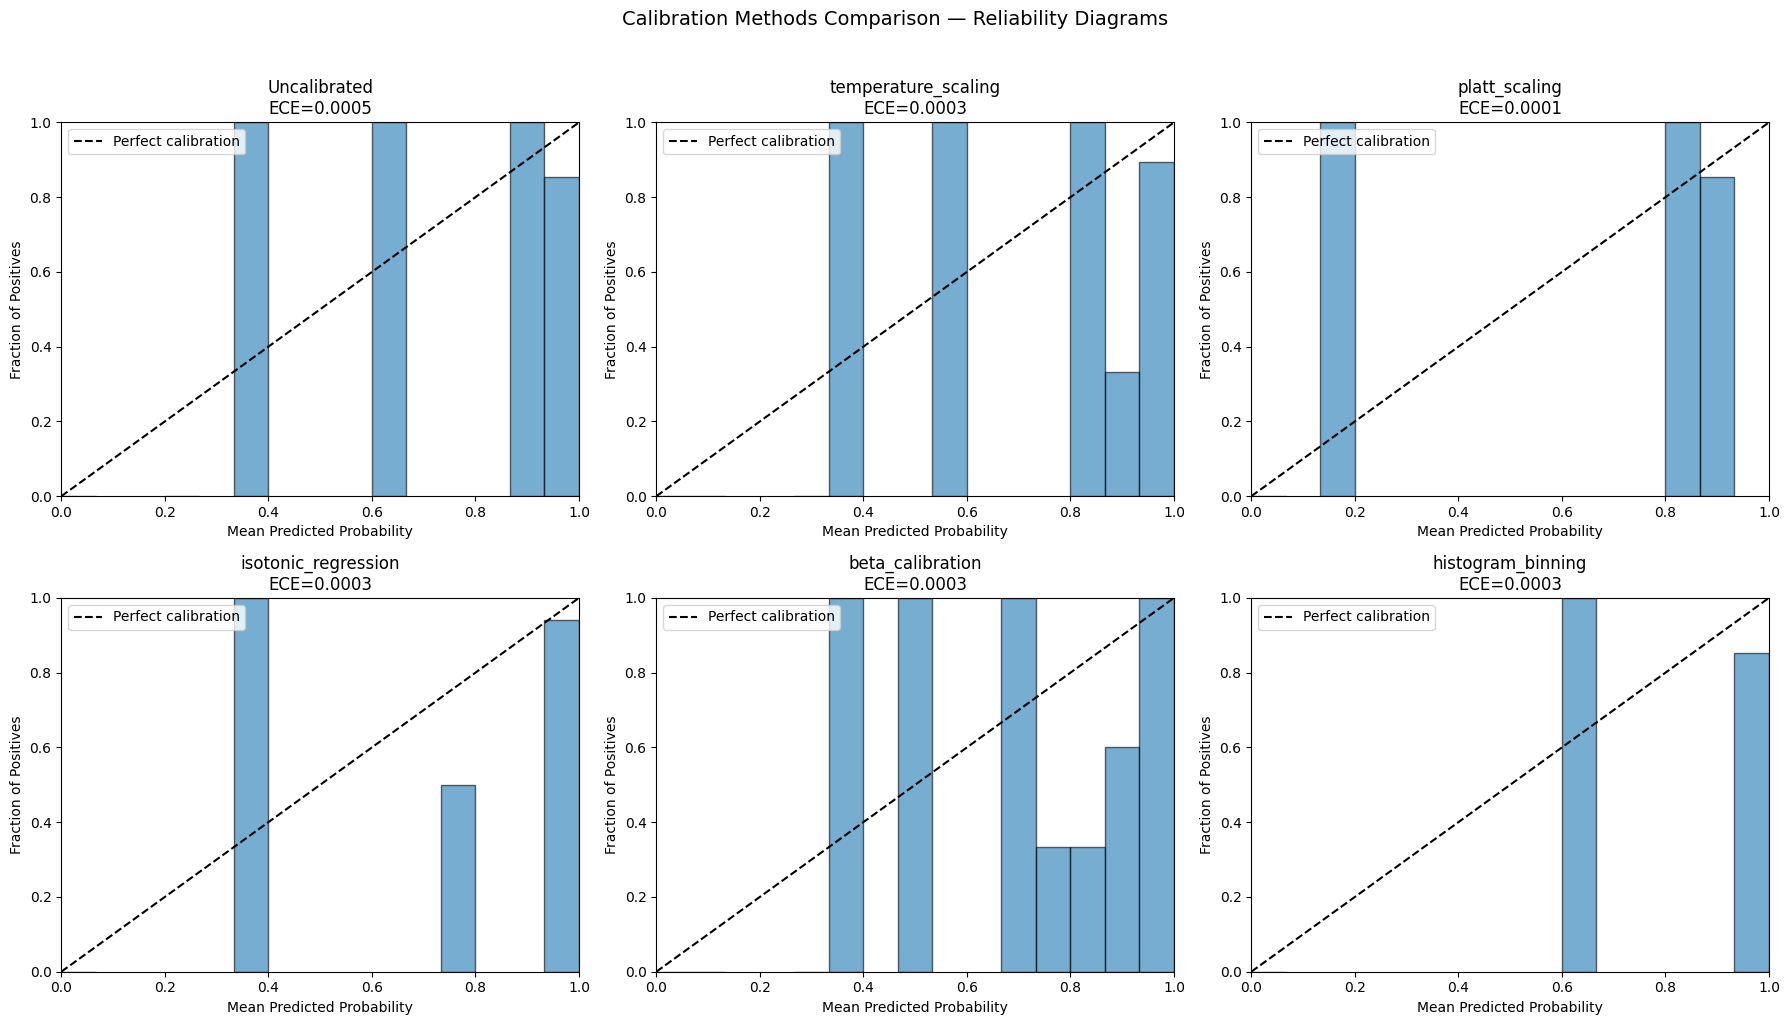

In [6]:
# Reliability diagrams for all methods
n = len(calibration_results)
cols = min(3, n)
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
axes = axes.flat if hasattr(axes, 'flat') else [axes]

for ax, (name, res) in zip(axes, calibration_results.items()):
    plot_reliability_diagram(
        res['probs'], y_test, n_bins=15,
        title=f'{name}\nECE={res["ece"]:.4f}',
        ax=ax
    )

for ax in axes[len(calibration_results):]:
    ax.set_visible(False)

plt.suptitle('Calibration Methods Comparison — Reliability Diagrams', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../results/figures/calibration_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Calibration Metrics Summary

In [7]:
summary = {}
for name, res in calibration_results.items():
    summary[name] = {k: v for k, v in res.items() if k != 'probs'}

summary_df = pd.DataFrame(summary).T
summary_df.index.name = 'Method'
summary_df = summary_df.sort_values('ece')
print(summary_df.to_markdown())
summary_df.to_csv('../results/tables/calibration_comparison.csv')
summary_df

| Method              |         ece |      mce |   brier_score |          nll |
|:--------------------|------------:|---------:|--------------:|-------------:|
| platt_scaling       | 0.000125883 | 0.807717 |   0.000486887 |   0.00349636 |
| histogram_binning   | 0.000275974 | 0.366667 |   0.000508627 |   0.00456268 |
| isotonic_regression | 0.000300166 | 0.653661 |   0.000462554 | nan          |
| temperature_scaling | 0.000327869 | 0.615884 |   0.000468691 |   0.00300325 |
| beta_calibration    | 0.000336613 | 0.660568 |   0.000445376 |   0.00284503 |
| Uncalibrated        | 0.000469548 | 0.651229 |   0.000476215 |   0.00373476 |


,ece,mce,brier_score,nll
Method,,,,
platt_scaling,0.000126,0.807717,0.000487,0.003496
histogram_binning,0.000276,0.366667,0.000509,0.004563
isotonic_regression,0.000300,0.653661,0.000463,NaN
temperature_scaling,0.000328,0.615884,0.000469,0.003003
beta_calibration,0.000337,0.660568,0.000445,0.002845
Uncalibrated,0.000470,0.651229,0.000476,0.003735


## Conformal Prediction Analysis

In [8]:
# Standard conformal prediction
alphas = [0.01, 0.05, 0.10, 0.20]
conformal_results = []

for alpha in alphas:
    cp = SplitConformalClassifier(alpha=alpha)
    cp.fit(raw_probs_cal, y_cal)
    eval_result = cp.evaluate_coverage(raw_probs_test, y_test)
    eval_result['alpha'] = alpha
    conformal_results.append(eval_result)
    print(f'alpha={alpha:.2f}: coverage={eval_result["empirical_coverage"]:.4f} '
          f'(target={1-alpha:.2f}), avg_set_size={eval_result["avg_set_size"]:.3f}')

# Cost-aware conformal
print('\nCost-Aware Conformal (fn_weight=10, fp_weight=1):')
for alpha in alphas:
    cp = CostAwareConformal(alpha=alpha, fn_cost_weight=10.0, fp_cost_weight=1.0)
    cp.fit(raw_probs_cal, y_cal)
    eval_result = cp.evaluate_coverage(raw_probs_test, y_test)
    print(f'  alpha={alpha:.2f}: coverage={eval_result["empirical_coverage"]:.4f}, '
          f'avg_set_size={eval_result["avg_set_size"]:.3f}')

alpha=0.01: coverage=0.9934 (target=0.99), avg_set_size=0.994
alpha=0.05: coverage=0.9634 (target=0.95), avg_set_size=0.964
alpha=0.10: coverage=0.9227 (target=0.90), avg_set_size=0.923
alpha=0.20: coverage=0.8368 (target=0.80), avg_set_size=0.837

Cost-Aware Conformal (fn_weight=10, fp_weight=1):
  alpha=0.01: coverage=0.9929, avg_set_size=0.993
  alpha=0.05: coverage=0.9634, avg_set_size=0.964
  alpha=0.10: coverage=0.9228, avg_set_size=0.923
  alpha=0.20: coverage=0.8368, avg_set_size=0.837


## Key Findings

1. Which calibration method produces the lowest ECE?
2. Does calibration improve or hurt Brier score?
3. How do parametric (temp scaling) vs non-parametric (isotonic) methods compare?
4. Does conformal prediction achieve the target coverage?
5. How does cost-aware conformal differ from standard conformal?